# Appendix A: Introduction to Python for Data Science

This notebook collects the runnable examples of *Appendix A: Introduction to Python for Data Science* from the textbook *Computational and Biological Intelligence* (A. Movasagh). Run the cells in order; each example is independent unless noted. Figures are also saved as PNG files in this folder.


In [1]:
%matplotlib inline

## Example A.1: Variables, data types, and operators

Script version: `example_A_1.py`

In [2]:
# Example A.1: Python basics — variables, data types, and operators
age = 52                      # int
temperature = 37.8            # float
name = "Patient-017"          # str
has_fever = temperature >= 37.5   # bool
 
print(type(age), type(temperature), type(name), type(has_fever))
print(f"{name}: age={age}, temp={temperature}°C, fever={has_fever}")
print("BMI example:", round(82 / 1.75 ** 2, 1))
print("Integer division and remainder:", 17 // 5, 17 % 5)

<class 'int'> <class 'float'> <class 'str'> <class 'bool'>
Patient-017: age=52, temp=37.8°C, fever=True
BMI example: 26.8
Integer division and remainder: 3 2


## Example A.2: Lists, tuples, dictionaries, and sets

Script version: `example_A_2.py`

In [3]:
# Example A.2: Data structures — lists, tuples, dictionaries, and sets
heart_rates = [72, 88, 95, 61, 110]           # list (mutable)
heart_rates.append(79)
print("List:", heart_rates, "| length:", len(heart_rates), "| max:", max(heart_rates))
print("Slicing first three:", heart_rates[:3], "| last:", heart_rates[-1])
 
shape = (512, 512, 3)                         # tuple (immutable)
print("Tuple:", shape, "| height:", shape[0])
 
patient = {"id": 17, "age": 52, "diagnosis": "benign"}   # dictionary
patient["follow_up"] = True
print("Dict keys:", list(patient.keys()), "| diagnosis:", patient["diagnosis"])
 
blood_types_a = {"A", "B", "O"}; blood_types_b = {"O", "AB"}  # sets
print("Union:", sorted(blood_types_a | blood_types_b), "| intersection:", blood_types_a & blood_types_b)
 
squares = [x ** 2 for x in range(6)]          # list comprehension
print("List comprehension:", squares)

List: [72, 88, 95, 61, 110, 79] | length: 6 | max: 110
Slicing first three: [72, 88, 95] | last: 79
Tuple: (512, 512, 3) | height: 512
Dict keys: ['id', 'age', 'diagnosis', 'follow_up'] | diagnosis: benign
Union: ['A', 'AB', 'B', 'O'] | intersection: {'O'}
List comprehension: [0, 1, 4, 9, 16, 25]


## Example A.3: Conditionals, loops, and functions

Script version: `example_A_3.py`

In [4]:
# Example A.3: Control structures and functions
def classify_bp(systolic, diastolic):
    """Classify blood pressure (simplified categories, for teaching only)."""
    if systolic < 120 and diastolic < 80:
        return "normal"
    elif systolic < 130 and diastolic < 80:
        return "elevated"
    elif systolic < 140 or diastolic < 90:
        return "stage 1"
    else:
        return "stage 2"
 
readings = [(115, 75), (125, 78), (135, 85), (150, 95)]
for s, d in readings:
    print(f"{s}/{d} mmHg -> {classify_bp(s, d)}")
 
count = 0
while count < 3:
    count += 1
print("while loop finished after", count, "iterations")
 
mean = lambda values: sum(values) / len(values)   # anonymous function
print("Mean systolic:", mean([s for s, _ in readings]))

115/75 mmHg -> normal
125/78 mmHg -> elevated
135/85 mmHg -> stage 1
150/95 mmHg -> stage 2
while loop finished after 3 iterations
Mean systolic: 131.25


## Example A.4: Arrays, axes, Boolean masks, and broadcasting

Script version: `example_A_4.py`

In [5]:
# Example A.4: NumPy arrays and vectorized computation
import numpy as np
 
a = np.array([1.0, 2.0, 3.0, 4.0])
M = np.arange(12).reshape(3, 4)
print("a * 2 =", a * 2, "| a ** 2 =", a ** 2)
print("M shape:", M.shape, "\nM =\n", M)
print("Column means:", M.mean(axis=0), "| row sums:", M.sum(axis=1))
print("Boolean mask M > 5:\n", M > 5)
print("Elements greater than 5:", M[M > 5])
print("Matrix product M @ M.T:\n", M @ M.T)
 
rng = np.random.default_rng(0)
x = rng.normal(loc=100, scale=15, size=10000)    # e.g. simulated IQ / lab values
print(f"Sample mean={x.mean():.2f}, std={x.std():.2f}, min={x.min():.1f}, max={x.max():.1f}")
print("Broadcasting (3x1) + (1x4):\n", np.array([[0], [10], [20]]) + np.array([1, 2, 3, 4]))

a * 2 = [2. 4. 6. 8.] | a ** 2 = [ 1.  4.  9. 16.]
M shape: (3, 4) 
M =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
Column means: [4. 5. 6. 7.] | row sums: [ 6 22 38]
Boolean mask M > 5:
 [[False False False False]
 [False False  True  True]
 [ True  True  True  True]]
Elements greater than 5: [ 6  7  8  9 10 11]
Matrix product M @ M.T:
 [[ 14  38  62]
 [ 38 126 214]
 [ 62 214 366]]
Sample mean=100.09, std=14.97, min=41.5, max=152.2
Broadcasting (3x1) + (1x4):
 [[ 1  2  3  4]
 [11 12 13 14]
 [21 22 23 24]]


## Example A.5: Three widely used types of plots

Script version: `example_A_5.py`

Figure saved with 3 subplots


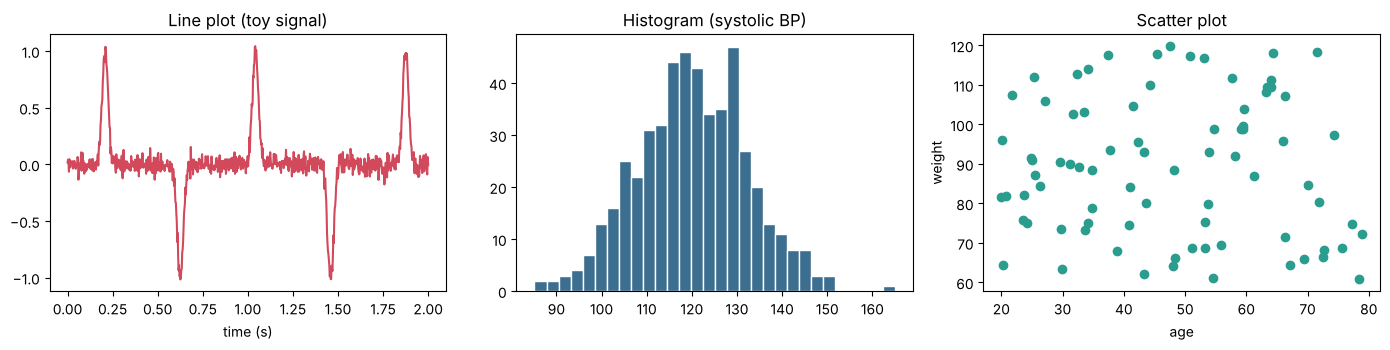

In [6]:
# Example A.5: Plotting with Matplotlib
import numpy as np
import matplotlib.pyplot as plt
 
rng = np.random.default_rng(1)
t = np.linspace(0, 2, 800)
ecg_like = np.sin(2 * np.pi * 1.2 * t) ** 63 + 0.05 * rng.normal(size=t.size)   # toy "ECG" spikes
values = rng.normal(120, 12, 500)
 
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(t, ecg_like, c="#d1495b"); ax[0].set_title("Line plot (toy signal)"); ax[0].set_xlabel("time (s)")
ax[1].hist(values, bins=30, color="#3C6E8F", edgecolor="white"); ax[1].set_title("Histogram (systolic BP)")
ax[2].scatter(rng.uniform(20, 80, 80), rng.uniform(60, 120, 80), c="#2a9d8f"); ax[2].set_title("Scatter plot")
ax[2].set_xlabel("age"); ax[2].set_ylabel("weight")
plt.tight_layout(); plt.savefig("figA_1.png", dpi=300)
print("Figure saved with", len(fig.axes), "subplots")

## Example A.6: Working with the breast cancer data table in Pandas

Script version: `example_A_6.py`

In [7]:
# Example A.6: Working with tabular data in Pandas
import pandas as pd
from sklearn.datasets import load_breast_cancer
 
data = load_breast_cancer(as_frame=True)
df = data.frame
df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})
 
print("Shape:", df.shape)
print(df[["mean radius", "mean texture", "diagnosis"]].head())
print("\nCounts per class:\n", df["diagnosis"].value_counts())
print("\nMean radius per class:\n", df.groupby("diagnosis")["mean radius"].mean().round(2))
print("\nMissing values in the whole table:", int(df.isna().sum().sum()))
large = df[df["mean radius"] > 20]
print("Tumors with mean radius > 20:", len(large), "| malignant share:",
      round((large["diagnosis"] == "malignant").mean(), 3))

Shape: (569, 32)
   mean radius  mean texture  diagnosis
0        17.99         10.38  malignant
1        20.57         17.77  malignant
2        19.69         21.25  malignant
3        11.42         20.38  malignant
4        20.29         14.34  malignant

Counts per class:
 diagnosis
benign       357
malignant    212
Name: count, dtype: int64

Mean radius per class:
 diagnosis
benign       12.15
malignant    17.46
Name: mean radius, dtype: float64

Missing values in the whole table: 0
Tumors with mean radius > 20: 45 | malignant share: 1.0
